In [1]:
import os, glob
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_mdl = os.path.join(pth_data, 'modeling')
pth_in = os.path.join(pth_mdl, 'inputs')
pth_mod = os.path.join(pth_data, 'features', 'biomart', 'modules')
pth_fig = os.path.join(pth, 'figures', 'preprocessing', 'spectrum')
pth_out = os.path.join(pth_mdl, 'spectrum')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'development.h5ad'))
adata.obs['t'] = adata.obs.t.astype(float); adata

AnnData object with n_obs × n_vars = 14458 × 14985
    obs: 'sample', 'celltype', 't', 'source'
    obsm: 'X_pca', 'X_umap', 'X_umap_traj'

In [4]:
mod_fn = sorted(glob.glob(os.path.join(pth_mod, '*.csv')))
get_name = lambda fn: os.path.split(fn)[1].replace('.csv', '')
mod_dict = {get_name(fn) : pd.read_csv(fn) for fn in mod_fn}

# module signatures
g_ref = mod_dict['ref'].mmusculus
for mod, df_mod in mod_dict.items():
    if mod != 'ref':
        print(mod)
        g = df_mod.mmusculus.copy()
        g = g.loc[g.isin(adata.var_names)]
        for _, df_group in adata.obs.groupby('source', observed = True):
            msk = adata.obs_names.isin(df_group.index)
            adata_group = adata[msk].copy()
            sc.tl.score_genes(adata_group,
                              gene_list = g,
                              score_name = mod,
                              ctrl_as_ref = False,
                              gene_pool = g_ref,
                              random_state = 1234)
            adata.obs.loc[msk, mod] = adata_group.obs[mod]

adata.obsm['X_spectrum'] = adata.obs[['late', 'early']].values

early
late


In [5]:
t_lim = {
    'GSE162534'         : [10, 1e5],
    'GSE229103'         : [6, 1e5],
    'rRNAModifications' : [0, 20]}

In [6]:
# select spectrum (t_min < t < t_max)
for src in adata.obs.source.cat.categories:
    msk = (adata.obs.source == src)
    (t_min, t_max), t = t_lim[src], adata[msk].obs.t
    spectrum = ((t > t_min) & (t < t_max)).astype(str)
    adata.obs.loc[msk, 'spectrum'] = spectrum
    print(src, (spectrum == 'True').sum())

GSE162534 2811
GSE229103 2190
rRNAModifications 1404


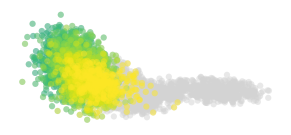

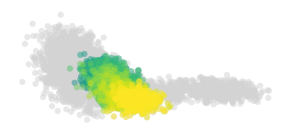

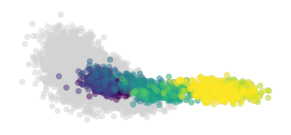

In [7]:
# plot spectrum (embeddings)
s, a, adata_plt = 80, .5, adata[adata.obs.spectrum == 'True'].copy()
for src, sdf in adata_plt.obs.groupby('source', observed = True):
    adata_src = adata_plt[sdf.index].copy()
    fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
    sc.pl.embedding(adata_plt, 'X_spectrum', size = s, alpha = a,
                    frameon = False, show = False, ax = ax)
    sc.pl.embedding(adata_src, 'X_spectrum', size = s, alpha = a,
                    color = 't', vmin = 0, colorbar_loc = None,
                    frameon = False, show = False, ax = ax)
    ax.set_title('')
    fn = os.path.join(pth_fig, f'{src}.pdf')
    plt.savefig(fn, bbox_inches = 'tight')

In [8]:
adata.write(os.path.join(pth_out, 'development.h5ad'))
adata

AnnData object with n_obs × n_vars = 14458 × 14985
    obs: 'sample', 'celltype', 't', 'source', 'early', 'late', 'spectrum'
    obsm: 'X_pca', 'X_umap', 'X_umap_traj', 'X_spectrum'